# Objects from materials

Objects sit one level above materials. An object is a piece of geometry
(canopy, roof, field, water, road) whose surface is a **material texture**
from `mlpsyn.materials`, so it inherits realistic grain.

Every point object shares the signature
`draw_x(ax, rng, budget, cx, cy, size, materials=None, rotation=None)` and
returns a normalised `(x0, y0, x1, y1)` bounding box. When `rotation` is
left as `None` the object picks a random orientation, so there is no
axis-aligned prior. Objects live in `mlpsyn.object.OBJECTS`.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches

from mlpsyn.materials import material_textures
from mlpsyn.object import OBJECTS, draw_object, draw_road
from mlpsyn.textures import ShapeBudget

import io


def check_figure_size(fig, max_mb=5.0):
    """Check that a figure's PNG stays below ``max_mb`` megabytes."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi)
    size_mb = buffer.getbuffer().nbytes / 1e6
    print(f"figure: {size_mb:.2f} MB")
    assert size_mb <= max_mb, f"figure too big: {size_mb:.2f} MB > {max_mb} MB"


### Visual analysis — 5 seeds per object

Objects drawn with material fills.

- **building** — material-filled roof, panels, rooftop units and a soft two-layer
  shadow; varies across seeds.
- **car / truck** — clear top-down vehicles (body, wheels, cabin / windshield or
  a longer box with a cab) that vary in colour and orientation.
- **tree / bush** — mottled canopies with small foliage highlights; stable
  across seeds.
- **conifer** — a soft radial fir crown: concentric smooth crowns with batched
  needle streaks and a small dark top. It is no longer a spiky dahlia/star
  (rebuilt in Round 31).
- **rock** — a rounded boulder silhouette with a lit facet and a shaded side.
- **field_plot** — material fill + oriented rows + outline, staying inside the
  rotated footprint.
- **pond / pool** — organic or rectangular water with soft sheen and, for the
  pool, a tiled deck border.
- **silo** — ribbed circular farm structure with a domed roof.
- **parking** — asphalt pad with stall lines and **car-sized** parked cars
  (fixed in Round 30), consistent with roadside cars.
- **plaza** — paved square with a fountain or planting.
- **hedgerow / orchard** — a line of small bushes along a field boundary; a grid
  of orchard trees.
- **greenhouse** — parallel gabled **glazed ranges** with a bright apex ridge,
  frame ribs and a soft block shadow (rebuilt in Round 34), no longer white
  blobs.
- **boat** — pointed hull, deck and a faint wake.

figure: 0.13 MB
figure: 0.14 MB


figure: 0.11 MB


figure: 0.15 MB
figure: 0.08 MB


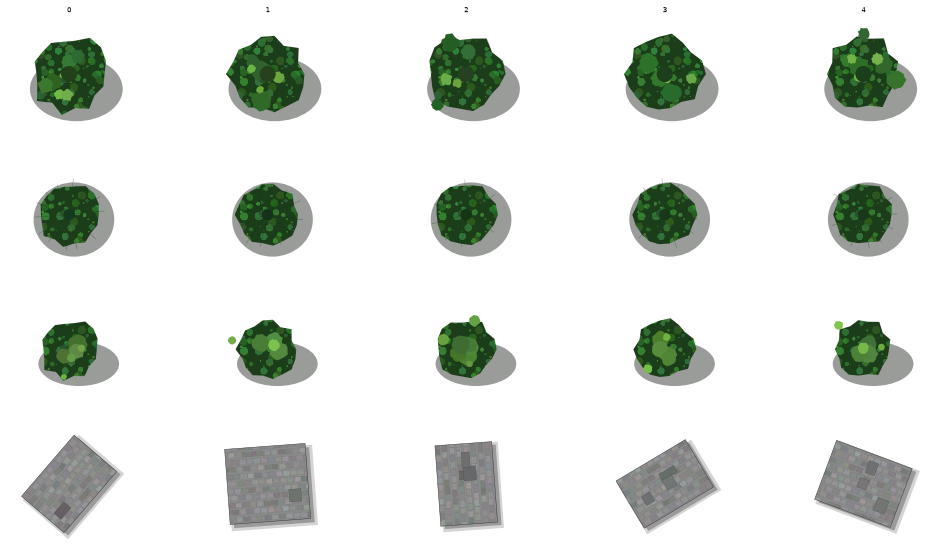

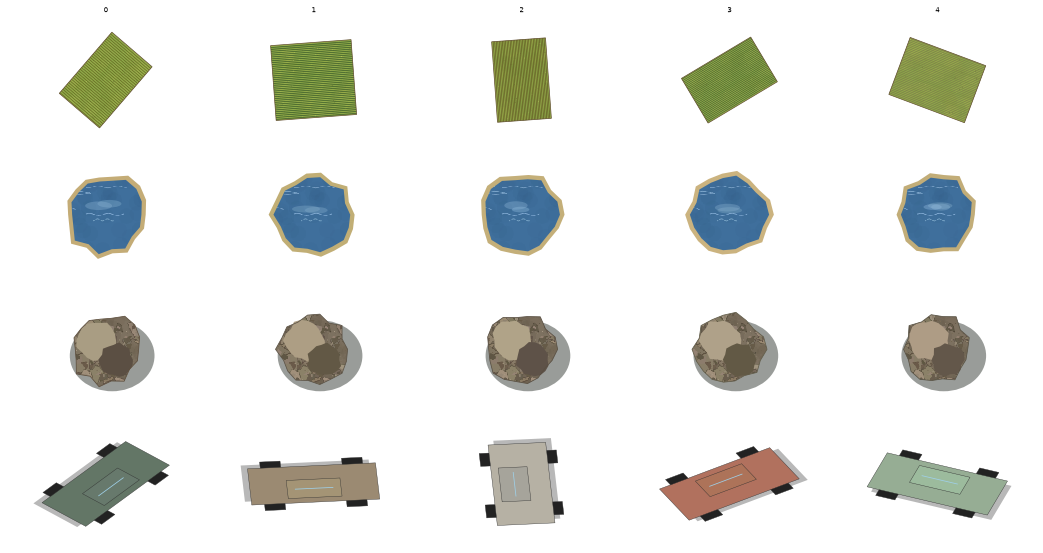

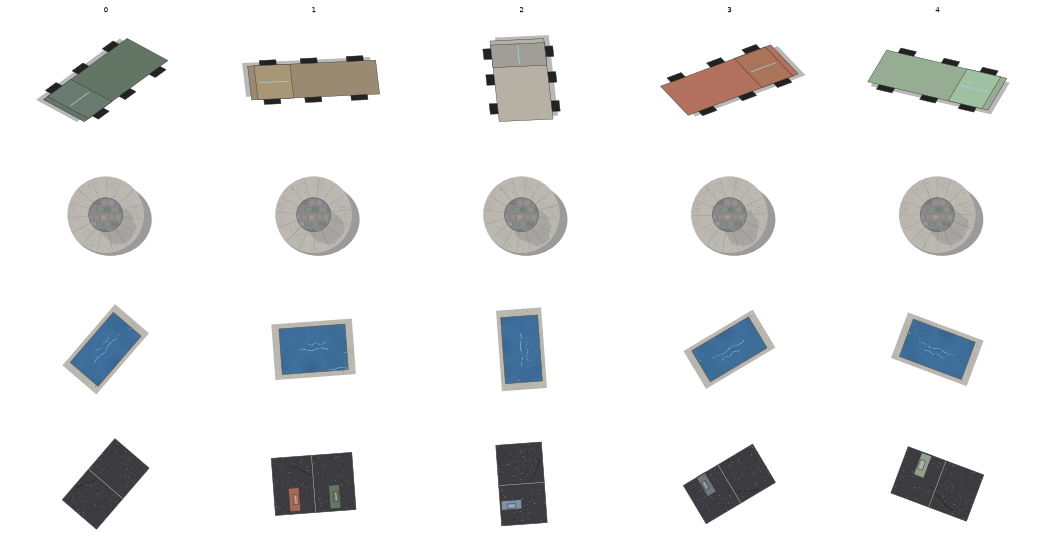

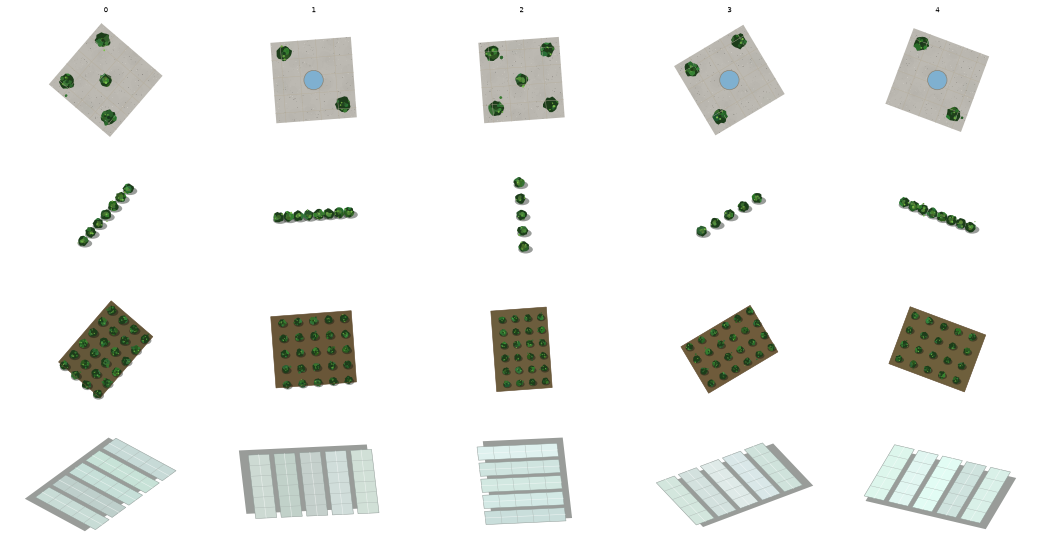

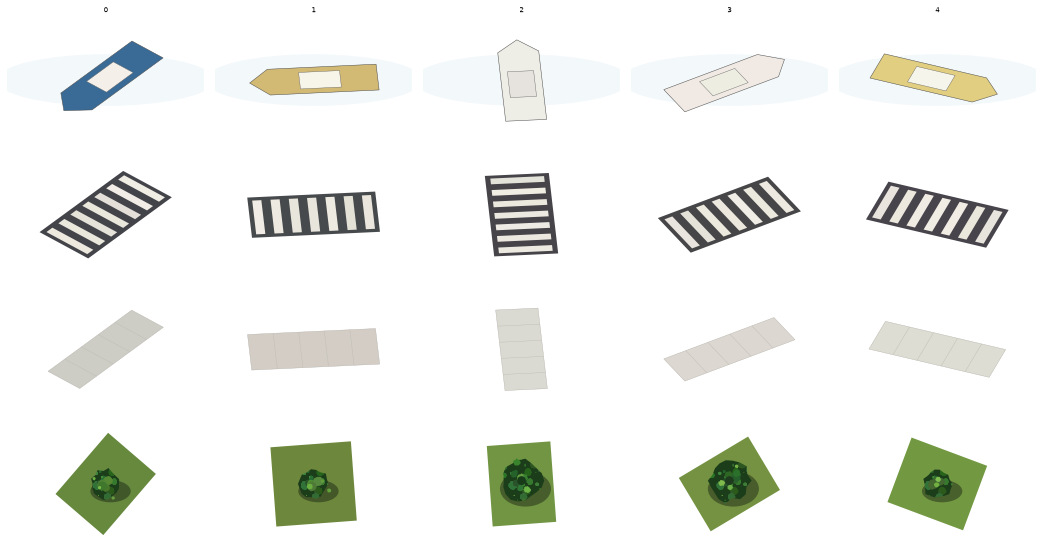

In [2]:
materials = material_textures(200, 0, ["foliage", "bark", "roof", "crop", "water", "rock", "concrete", "asphalt"])
seeds = list(range(5))  # five instances per object

for group in [list(OBJECTS)[i:i + 4] for i in range(0, len(OBJECTS), 4)]:
    fig, axes = plt.subplots(len(group), len(seeds), figsize=(15, 2.0 * len(group)), dpi=70)
    axes = np.atleast_2d(axes)
    for row, name in enumerate(group):
        for col, seed in enumerate(seeds):
            ax = axes[row, col]
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.set_axis_off()
            ax.set_facecolor("#dcdcdc")
            OBJECTS[name](
                ax, np.random.default_rng(seed), ShapeBudget(), 0.5, 0.5, 0.65, materials=materials
            )
            ax.set_ylabel(name, fontsize=8)
            if row == 0:
                ax.set_title(f"{seed}", fontsize=7)
    plt.tight_layout()
    check_figure_size(fig)
plt.show()

### Visual analysis — 5 seeds per object

Objects drawn with material fills.

- **building** — material-filled roof, panels, rooftop units and a soft two-layer
  shadow; varies across seeds.
- **car / truck** — clear top-down vehicles (body, wheels, cabin / windshield or
  a longer box with a cab) that vary in colour and orientation.
- **tree / bush** — mottled canopies with small foliage highlights; stable
  across seeds.
- **conifer** — a soft radial fir crown: concentric smooth crowns with batched
  needle streaks and a small dark top. It is no longer a spiky dahlia/star
  (rebuilt in Round 31).
- **rock** — a rounded boulder silhouette with a lit facet and a shaded side.
- **field_plot** — material fill + oriented rows + outline, staying inside the
  rotated footprint.
- **pond / pool** — organic or rectangular water with soft sheen and, for the
  pool, a tiled deck border.
- **silo** — ribbed circular farm structure with a domed roof.
- **parking** — asphalt pad with stall lines and **car-sized** parked cars
  (fixed in Round 30), consistent with roadside cars.
- **plaza** — paved square with a fountain or planting.
- **hedgerow / orchard** — a line of small bushes along a field boundary; a grid
  of orchard trees.
- **greenhouse** — parallel gabled **glazed ranges** with a bright apex ridge,
  frame ribs and a soft block shadow (rebuilt in Round 34), no longer white
  blobs.
- **boat** — pointed hull, deck and a faint wake.

## No axis-aligned prior

The same object can be requested at any orientation. Passing an explicit
`rotation` shows how much the shape varies, while the default picks a
random angle.

figure: 0.23 MB


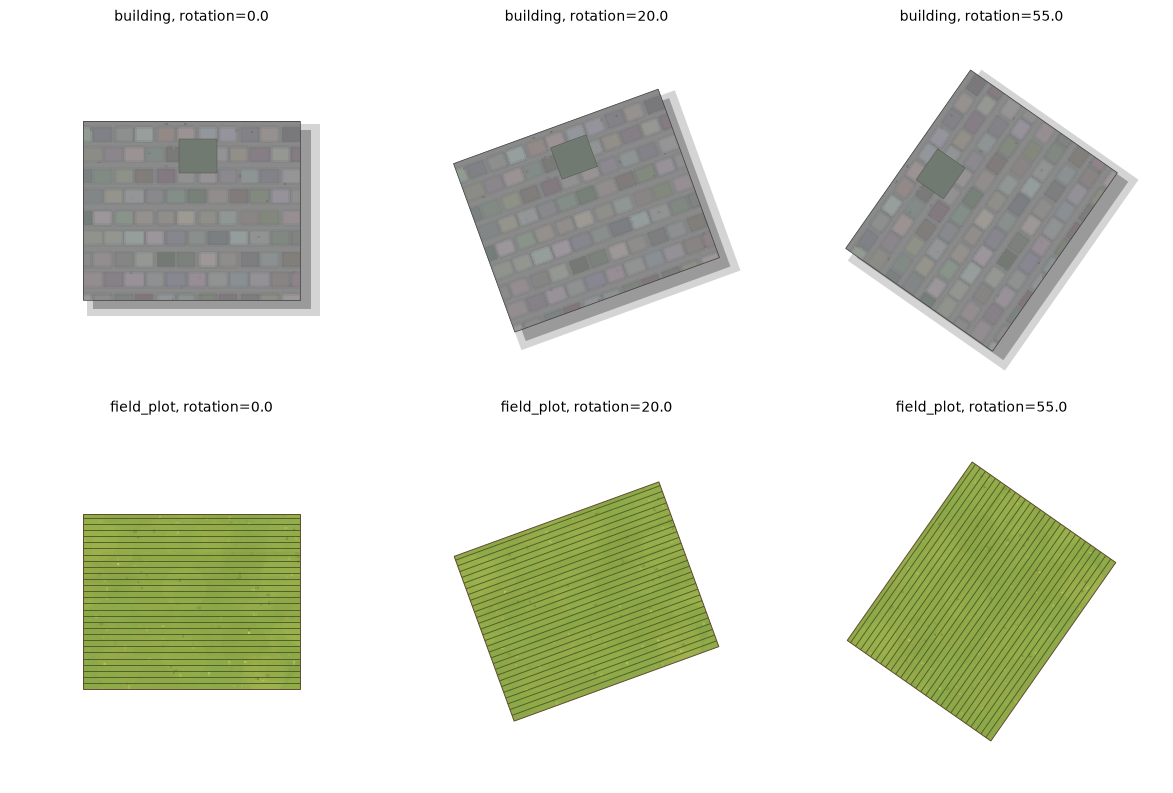

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for col, rotation in enumerate([0.0, 20.0, 55.0]):
    for row, name in enumerate(["building", "field_plot"]):
        ax = axes[row, col]
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_axis_off()
        ax.set_facecolor("#dcdcdc")
        OBJECTS[name](ax, np.random.default_rng(0), ShapeBudget(), 0.5, 0.5, 0.6,
                      materials=materials, rotation=rotation)
        ax.set_title(f"{name}, rotation={rotation}", fontsize=10)
plt.tight_layout()
check_figure_size(fig)
plt.show()

### Visual analysis — rotation

The material fill now rotates with the footprint at every angle (0°, 20°, 55°):
the texture grain, the thin outline and the bounding box all coincide, with no
spill and no "extra outline". (The previous round exposed a bug where
`fill_patch` clipped the rotated texture with the unrotated rectangle; it is now
fixed with `TransformedPatchPath`.) The building keeps its offset shadow and
rooftop units at all angles.

## Bounding boxes

Each object returns its axis-aligned bounding box, so object-level
annotations fall out for free.

figure: 0.03 MB


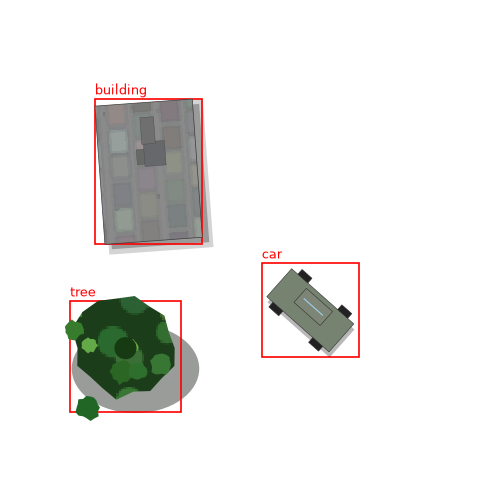

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_axis_off()
ax.set_facecolor("#dcdcdc")
rng = np.random.default_rng(2)
budget = ShapeBudget()
objects = [
    ("building", 0.3, 0.65, 0.3),
    ("car", 0.65, 0.35, 0.18),
    ("tree", 0.25, 0.25, 0.24),
]
for name, cx, cy, size in objects:
    x0, y0, x1, y1 = draw_object(name, ax, rng, budget, cx, cy, size, materials=materials)
    ax.add_patch(
        patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=1.2)
    )
    ax.text(x0, y1 + 0.01, name, color="red", fontsize=9)
check_figure_size(fig)
plt.show()

### Visual analysis — bounding boxes

The returned `(x0, y0, x1, y1)` boxes (red) tightly enclose the building, tree
and car. The building box matches the rotated footprint, the car box includes
the wheels and the tree box includes the canopy, so object-level annotations are
accurate for these three objects.

## Roads

Roads are filled with the `asphalt` material and can bow.

shapes used: 6
figure: 0.02 MB


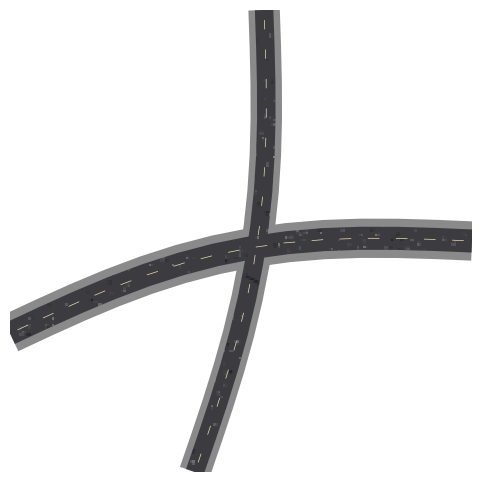

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_axis_off()
rng = np.random.default_rng(3)
budget = ShapeBudget()
draw_road(ax, rng, budget, (0.0, 0.3), (1.0, 0.5), width=0.05, materials=materials, curve=0.08)
draw_road(ax, rng, budget, (0.4, 0.0), (0.55, 1.0), width=0.04, materials=materials, curve=-0.06)
print("shapes used:", budget.count)
check_figure_size(fig)
plt.show()

### Visual analysis — roads

Two asphalt ribbons with a dashed centreline and a grey shoulder; the bow
(`curve`) reads as a gentle S-bend and the crossing is clean. Roads are not
annotated as objects (only point objects are).